In [14]:
# Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('../../../results/figures/ml', exist_ok=True)
os.makedirs('../../../results/tables', exist_ok=True)
os.makedirs('../../models', exist_ok=True)

df = pd.read_csv('../../../data/processed/df_final.csv')
print("Loaded df_final.csv:", df.shape)
print(f"Columns: {df.columns.tolist()}")

Loaded df_final.csv: (28028, 24)
Columns: ['player_id', 'player_name', 'total_goals', 'total_assists', 'total_yellow', 'total_red', 'total_minutes', 'total_games', 'goal_contribution', 'position', 'sub_position', 'country_of_citizenship', 'height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals', 'age', 'position_encoded', 'sub_position_encoded', 'goals_per_90', 'assists_per_90', 'goal_contribution_per_90', 'minutes_per_game']


In [15]:
# ============================================================
# Define Features + Target
# ============================================================

df_ml = df.copy()

# Numerical features
NUMERICAL_FEATURES = [
    'total_goals',
    'total_assists',
    'total_yellow',
    'total_red',
    'total_minutes',
    'total_games',
    'goal_contribution',
    'height_in_cm',
    'age',
    'international_caps',
    'international_goals'
]

# Nominal categorical features
# Keep them as raw categories here.
# Encoding will be fitted ONLY on training data inside the pipeline.
CATEGORICAL_FEATURES = [
    'position',
    'sub_position'
]

# Complete feature list
FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

# Target
TARGET = 'market_value_in_eur'

X = df_ml[FEATURES].copy()

# Log-transform target because market value is strongly right-skewed
y = np.log1p(df_ml[TARGET])

print("Features:", X.shape)
print("Target  :", y.shape)

print(f"\nFeatures used ({len(FEATURES)}):")
for i, feature in enumerate(FEATURES, 1):
    print(f"  {i:2}. {feature}")

print(f"\nTarget: {TARGET}")
print("Target transformation: log1p")

Features: (28028, 13)
Target  : (28028,)

Features used (13):
   1. total_goals
   2. total_assists
   3. total_yellow
   4. total_red
   5. total_minutes
   6. total_games
   7. goal_contribution
   8. height_in_cm
   9. age
  10. international_caps
  11. international_goals
  12. position
  13. sub_position

Target: market_value_in_eur
Target transformation: log1p


 Train/Test Split (80/20):
  Train : 22,422 players (80%)
  Test  : 5,606 players (20%)


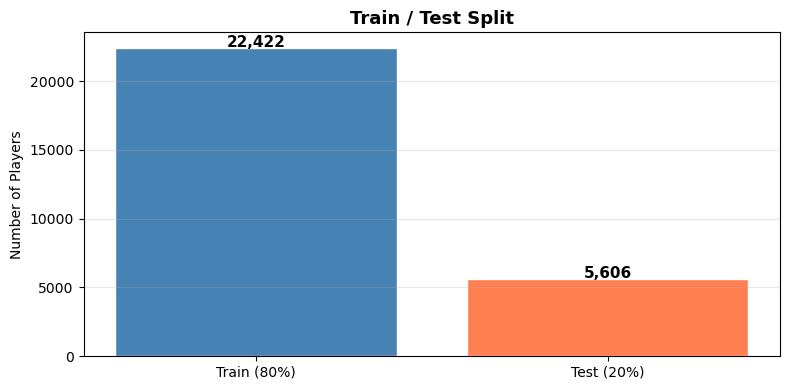

 Saved


In [16]:
# Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(" Train/Test Split (80/20):")
print(f"  Train : {X_train.shape[0]:,} players ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"  Test  : {X_test.shape[0]:,} players ({X_test.shape[0]/len(X)*100:.0f}%)")

# Visualize split
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(['Train (80%)', 'Test (20%)'],
       [len(X_train), len(X_test)],
       color=['steelblue', 'coral'], edgecolor='white')
ax.set_title('Train / Test Split', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Players')
for i, v in enumerate([len(X_train), len(X_test)]):
    ax.text(i, v + 50, f'{v:,}', ha='center', fontsize=11, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../../../results/figures/ml/01_train_test_split.png', dpi=150)
plt.show()
print(" Saved")

In [17]:
# ============================================================
# Build Preprocessing + Model Pipelines
# ============================================================

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# Combine numerical + categorical preprocessing
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, NUMERICAL_FEATURES),
    ('cat', categorical_pipeline, CATEGORICAL_FEATURES)
])

# ------------------------------------------------------------
# Model 1: Linear Regression
# ------------------------------------------------------------
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# ------------------------------------------------------------
# Model 2: Random Forest
# ------------------------------------------------------------
pipeline_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# Model 3: Gradient Boosting
# ------------------------------------------------------------
pipeline_gb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    ))
])

models = {
    'Linear Regression': pipeline_lr,
    'Random Forest': pipeline_rf,
    'Gradient Boosting': pipeline_gb
}

print("3 ML pipelines built successfully.")
print("Numerical     : Median Imputer -> StandardScaler")
print("Categorical   : Most-Frequent Imputer -> OneHotEncoder")
print("Models        : Linear Regression, Random Forest, Gradient Boosting")
print("\nPreprocessing will be fitted on TRAINING DATA only.")

3 ML pipelines built successfully.
Numerical     : Median Imputer -> StandardScaler
Categorical   : Most-Frequent Imputer -> OneHotEncoder
Models        : Linear Regression, Random Forest, Gradient Boosting

Preprocessing will be fitted on TRAINING DATA only.


In [18]:
# Train + Evaluate All Models

results = []

for name, pipeline in models.items():
    print(f"Training {name}...")

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Convert back from log scale
    y_test_actual = np.expm1(y_test)
    y_pred_actual = np.expm1(y_pred)

    # Metrics
    mae = mean_absolute_error(y_test_actual, y_pred_actual)
    mse = mean_squared_error(y_test_actual, y_pred_actual)
    r2  = r2_score(y_test, y_pred)

    results.append({
        'Model' : name,
        'MAE'   : round(mae, 2),
        'MSE'   : round(mse, 2),
        'R2'    : round(r2, 4)
    })
    print(f"   MAE: €{mae:,.0f} | R²: {r2:.4f}\n")

results_df = pd.DataFrame(results)
results_df.to_csv('../../../results/tables/model_comparison.csv', index=False)

print("=" * 55)
print(" Model Comparison:")
print(results_df.to_string(index=False))
print("\n Saved model_comparison.csv")

Training Linear Regression...
   MAE: €1,728,789 | R²: 0.3921

Training Random Forest...
   MAE: €1,300,232 | R²: 0.5772

Training Gradient Boosting...
   MAE: €1,318,255 | R²: 0.5978

 Model Comparison:
            Model        MAE          MSE     R2
Linear Regression 1728788.93 4.466984e+13 0.3921
    Random Forest 1300232.44 2.155508e+13 0.5772
Gradient Boosting 1318254.64 2.331874e+13 0.5978

 Saved model_comparison.csv


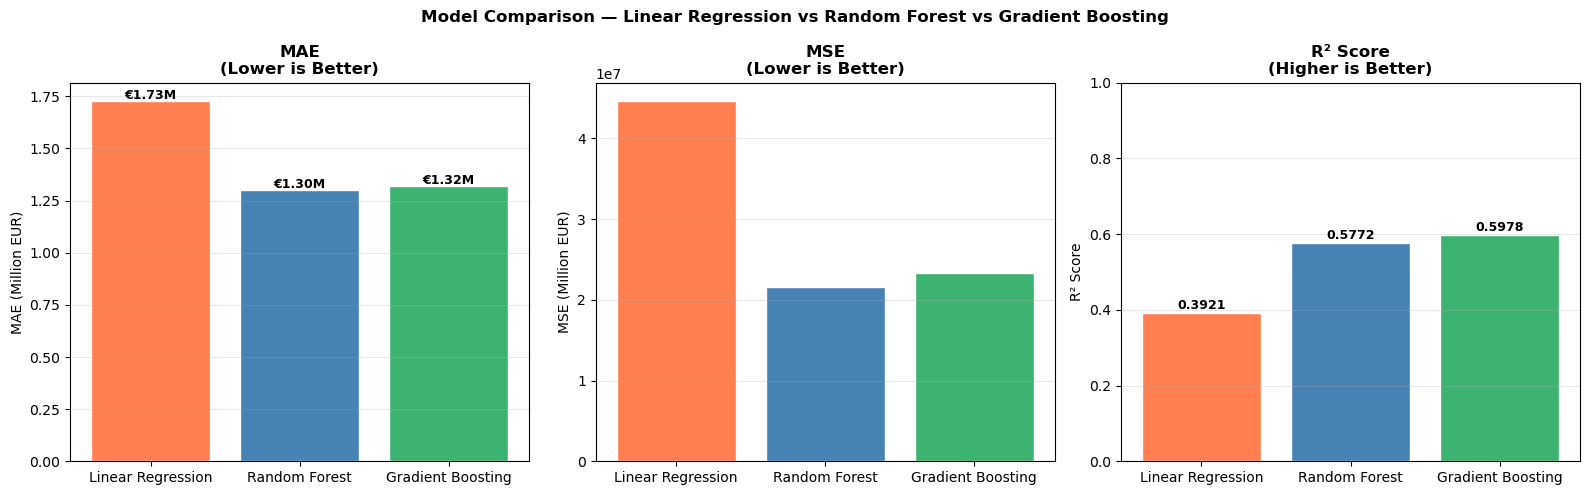

 Saved


In [19]:
# Model Comparison Chart

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['coral', 'steelblue', 'mediumseagreen']

# MAE — lower is better
axes[0].bar(results_df['Model'],
            results_df['MAE'] / 1_000_000,
            color=colors, edgecolor='white')
axes[0].set_title('MAE\n(Lower is Better)',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('MAE (Million EUR)')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(results_df['MAE'] / 1_000_000):
    axes[0].text(i, v + 0.01, f'€{v:.2f}M',
                 ha='center', fontsize=9, fontweight='bold')

# MSE — lower is better
axes[1].bar(results_df['Model'],
            results_df['MSE'] / 1_000_000,
            color=colors, edgecolor='white')
axes[1].set_title('MSE\n(Lower is Better)',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('MSE (Million EUR)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

# R² — higher is better
axes[2].bar(results_df['Model'],
            results_df['R2'],
            color=colors, edgecolor='white')
axes[2].set_title('R² Score\n(Higher is Better)',
                  fontsize=12, fontweight='bold')
axes[2].set_ylabel('R² Score')
axes[2].set_ylim(0, 1)
axes[2].tick_params(axis='x', rotation=0)
axes[2].grid(axis='y', alpha=0.3)
for i, v in enumerate(results_df['R2']):
    axes[2].text(i, v + 0.01, f'{v:.4f}',
                 ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Model Comparison — Linear Regression vs Random Forest vs Gradient Boosting',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/ml/02_model_comparison.png', dpi=150)
plt.show()
print(" Saved")

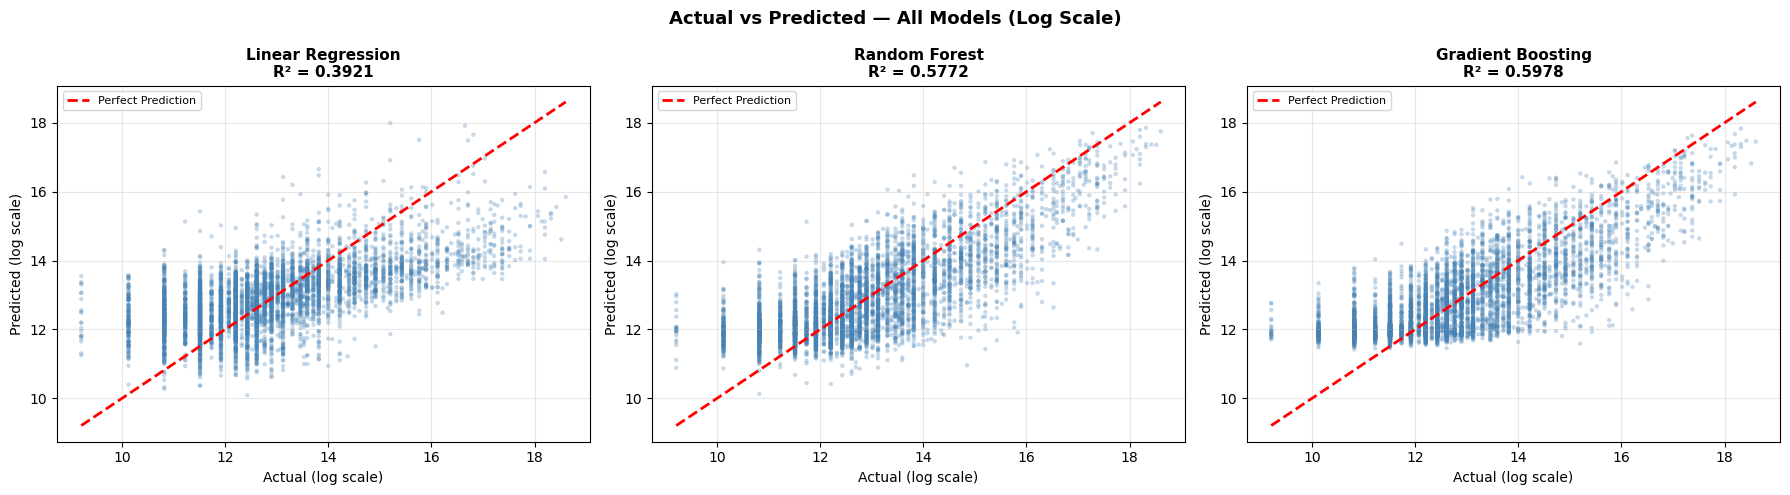

 Saved


In [20]:
# Actual & Predicted

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipeline) in zip(axes, models.items()):
    y_pred = pipeline.predict(X_test)
    r2     = r2_score(y_test, y_pred)

    ax.scatter(y_test, y_pred,
               alpha=0.3, color='steelblue',
               edgecolors='none', s=10)
    ax.plot([y_test.min(), y_test.max()],
            [y_test.min(), y_test.max()],
            'r--', linewidth=2, label='Perfect Prediction')
    ax.set_title(f'{name}\nR² = {r2:.4f}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Actual (log scale)')
    ax.set_ylabel('Predicted (log scale)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Actual vs Predicted — All Models (Log Scale)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/ml/03_actual_vs_predicted.png', dpi=150)
plt.show()
print(" Saved")

In [21]:
# ============================================================
# 5-Fold Cross-Validation
# Preprocessing is performed INSIDE each CV fold
# ============================================================

from sklearn.model_selection import KFold, cross_val_score
import pandas as pd
import numpy as np

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, pipeline in models.items():

    print(f"Cross-validating {name}...")

    # Use training data only
    # Pipeline handles imputation, scaling and OneHotEncoding
    # separately inside each CV fold
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV_R2_Mean': scores.mean(),
        'CV_R2_Std': scores.std()
    })

    print(f"  Fold R²: {np.round(scores, 4)}")
    print(f"  Mean R²: {scores.mean():.4f}")
    print(f"  Std     : {scores.std():.4f}")
    print()

cv_df = pd.DataFrame(cv_results)

print("=" * 55)
print("5-Fold Cross-Validation Results")
print("=" * 55)

print(
    cv_df.to_string(
        index=False,
        formatters={
            'CV_R2_Mean': '{:.4f}'.format,
            'CV_R2_Std': '{:.4f}'.format
        }
    )
)

Cross-validating Linear Regression...
  Fold R²: [0.3695 0.374  0.3722 0.3777 0.3666]
  Mean R²: 0.3720
  Std     : 0.0038

Cross-validating Random Forest...
  Fold R²: [0.5642 0.5768 0.5952 0.5762 0.5712]
  Mean R²: 0.5768
  Std     : 0.0103

Cross-validating Gradient Boosting...
  Fold R²: [0.5812 0.5935 0.6076 0.5831 0.5853]
  Mean R²: 0.5901
  Std     : 0.0097

5-Fold Cross-Validation Results
            Model CV_R2_Mean CV_R2_Std
Linear Regression     0.3720    0.0038
    Random Forest     0.5768    0.0103
Gradient Boosting     0.5901    0.0097


In [22]:
# ============================================================
# Aggregated Random Forest Feature Importance
# ============================================================

rf_model = pipeline_rf.named_steps['model']
rf_preprocessor = pipeline_rf.named_steps['preprocessor']

# Feature names after One-Hot Encoding
feature_names = rf_preprocessor.get_feature_names_out()

# Importance from fitted Random Forest
importances = rf_model.feature_importances_

detailed_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Aggregate One-Hot columns back to original conceptual features
aggregated = {}

for _, row in detailed_importance.iterrows():

    feature = row['Feature']
    importance = row['Importance']

    # Numerical features
    if feature.startswith('num__'):
        original_feature = feature.replace('num__', '')

    # Position One-Hot features
    elif feature.startswith('cat__position_'):
        original_feature = 'position'

    # Sub-position One-Hot features
    elif feature.startswith('cat__sub_position_'):
        original_feature = 'sub_position'

    else:
        original_feature = feature

    aggregated[original_feature] = (
        aggregated.get(original_feature, 0) + importance
    )

feature_importance = pd.DataFrame({
    'Feature': aggregated.keys(),
    'Importance': aggregated.values()
}).sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

print("=" * 55)
print("Aggregated Feature Importance")
print("=" * 55)

print(feature_importance.to_string(index=False))

print("\nTotal features:", len(feature_importance))
print(
    "Total importance:",
    round(feature_importance['Importance'].sum(), 4)
)

Aggregated Feature Importance
            Feature  Importance
 international_caps    0.302723
                age    0.188730
      total_minutes    0.127127
        total_games    0.105179
  goal_contribution    0.073194
       height_in_cm    0.059878
       sub_position    0.041194
       total_yellow    0.034064
      total_assists    0.021517
        total_goals    0.020727
           position    0.012520
international_goals    0.006841
          total_red    0.006307

Total features: 13
Total importance: 1.0


In [23]:
print("cv_df columns:")
print(cv_df.columns.tolist())

print("\ncv_df:")
display(cv_df)

cv_df columns:
['Model', 'CV_R2_Mean', 'CV_R2_Std']

cv_df:


,Model,CV_R2_Mean,CV_R2_Std
0,Linear Regression,0.371993,0.003777
1,Random Forest,0.576751,0.010286
2,Gradient Boosting,0.590131,0.009692


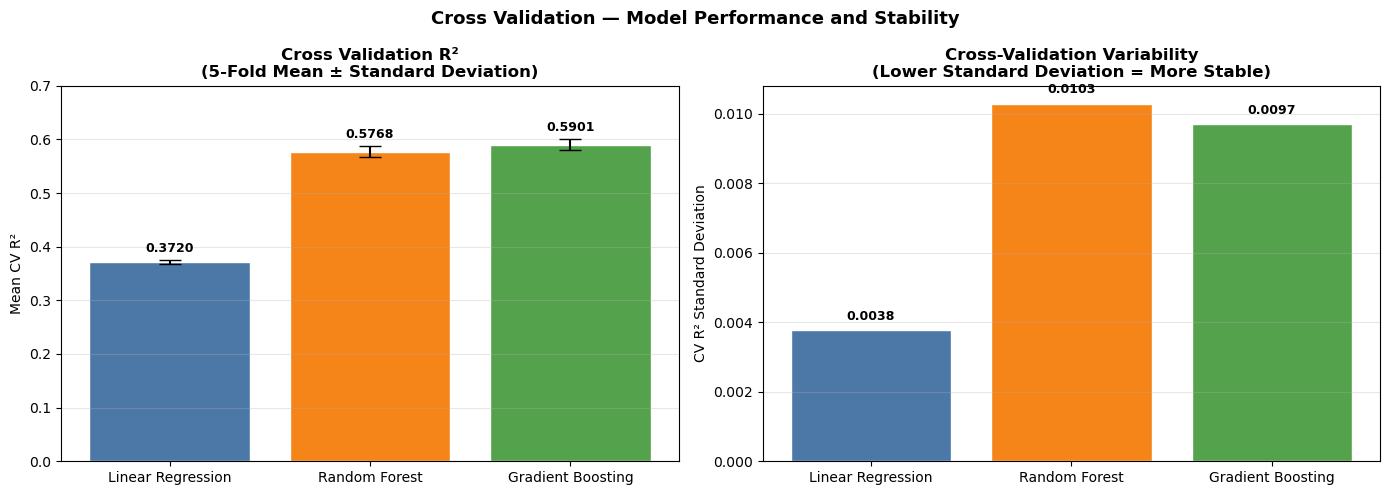

Saved


In [24]:
# ============================================================
# Cross-Validation Visualization
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#4C78A8', '#F58518', '#54A24B']

# ============================================================
# Plot 1 — Mean CV R² with Standard Deviation
# ============================================================

axes[0].bar(
    cv_df['Model'],
    cv_df['CV_R2_Mean'],
    yerr=cv_df['CV_R2_Std'],
    color=colors,
    edgecolor='white',
    capsize=8
)

axes[0].set_title(
    'Cross Validation R²\n(5-Fold Mean ± Standard Deviation)',
    fontsize=12,
    fontweight='bold'
)

axes[0].set_ylabel('Mean CV R²')
axes[0].set_ylim(0, 0.70)
axes[0].grid(axis='y', alpha=0.3)

for i, row in cv_df.iterrows():

    axes[0].text(
        i,
        row['CV_R2_Mean'] + row['CV_R2_Std'] + 0.015,
        f"{row['CV_R2_Mean']:.4f}",
        ha='center',
        fontsize=9,
        fontweight='bold'
    )


# ============================================================
# Plot 2 — CV Stability (Standard Deviation)
# ============================================================

axes[1].bar(
    cv_df['Model'],
    cv_df['CV_R2_Std'],
    color=colors,
    edgecolor='white'
)

axes[1].set_title(
    'Cross-Validation Variability\n(Lower Standard Deviation = More Stable)',
    fontsize=12,
    fontweight='bold'
)

axes[1].set_ylabel('CV R² Standard Deviation')
axes[1].grid(axis='y', alpha=0.3)

for i, row in cv_df.iterrows():

    axes[1].text(
        i,
        row['CV_R2_Std'] + 0.0003,
        f"{row['CV_R2_Std']:.4f}",
        ha='center',
        fontsize=9,
        fontweight='bold'
    )


# ============================================================
# Final Layout
# ============================================================

plt.suptitle(
    'Cross Validation — Model Performance and Stability',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    '../../../results/figures/ml/04_cross_validation.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("Saved")

In [ ]:
# ============================================================
# Feature Selection Experiment
# Top 3 / Top 5 / Top 8 / Top 10 / All 13
# Selection and evaluation use TRAINING DATA only
# ============================================================


from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

# Ranking obtained from Random Forest feature importance
feature_ranking = feature_importance['Feature'].tolist()

feature_sets = {
    'Top 3': feature_ranking[:3],
    'Top 5': feature_ranking[:5],
    'Top 8': feature_ranking[:8],
    'Top 10': feature_ranking[:10],
    'All 13': feature_ranking
}

feature_selection_results = []

for set_name, selected_features in feature_sets.items():

    print("=" * 60)
    print(f"{set_name} ({len(selected_features)} features)")
    print(selected_features)

    # Separate numeric and categorical features for this subset
    selected_numeric = [
        f for f in selected_features
        if f in NUMERICAL_FEATURES
    ]

    selected_categorical = [
        f for f in selected_features
        if f in CATEGORICAL_FEATURES
    ]

    # Numerical preprocessing
    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    transformers = []

    if selected_numeric:
        transformers.append(
            ('num', numeric_transformer, selected_numeric)
        )

    if selected_categorical:
        categorical_transformer = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ])

        transformers.append(
            ('cat', categorical_transformer, selected_categorical)
        )

    subset_preprocessor = ColumnTransformer(
        transformers=transformers
    )

    # Gradient Boosting = strongest CV baseline
    subset_model = Pipeline([
        ('preprocessor', subset_preprocessor),
        ('model', GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        ))
    ])

    # IMPORTANT:
    # Only training data is used here.
    X_subset = X_train[selected_features]

    cv_scores = cross_val_score(
        subset_model,
        X_subset,
        y_train,
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    feature_selection_results.append({
        'Feature_Set': set_name,
        'N_Features': len(selected_features),
        'CV_R2_Mean': cv_scores.mean(),
        'CV_R2_Std': cv_scores.std()
    })

    print(f"Fold R² : {np.round(cv_scores, 4)}")
    print(f"Mean R² : {cv_scores.mean():.4f}")
    print(f"Std     : {cv_scores.std():.4f}")


feature_selection_df = pd.DataFrame(
    feature_selection_results
)

print("\n" + "=" * 60)
print("FEATURE SELECTION COMPARISON")
print("=" * 60)

print(
    feature_selection_df.to_string(
        index=False,
        formatters={
            'CV_R2_Mean': '{:.4f}'.format,
            'CV_R2_Std': '{:.4f}'.format
        }
    )
)

Top 3 (3 features)
['international_caps', 'age', 'total_minutes']
Fold R² : [0.5762 0.5861 0.5983 0.5778 0.5826]
Mean R² : 0.5842
Std     : 0.0079
Top 5 (5 features)
['international_caps', 'age', 'total_minutes', 'total_games', 'goal_contribution']
Fold R² : [0.5816 0.5948 0.6089 0.5836 0.5875]
Mean R² : 0.5913
Std     : 0.0099
Top 8 (8 features)
['international_caps', 'age', 'total_minutes', 'total_games', 'goal_contribution', 'height_in_cm', 'sub_position', 'total_yellow']
Fold R² : [0.5828 0.5937 0.6089 0.5847 0.5885]
Mean R² : 0.5917
Std     : 0.0094
Top 10 (10 features)
['international_caps', 'age', 'total_minutes', 'total_games', 'goal_contribution', 'height_in_cm', 'sub_position', 'total_yellow', 'total_assists', 'total_goals']
Fold R² : [0.5816 0.594  0.6067 0.5844 0.5874]
Mean R² : 0.5908
Std     : 0.0089
All 13 (13 features)
['international_caps', 'age', 'total_minutes', 'total_games', 'goal_contribution', 'height_in_cm', 'sub_position', 'total_yellow', 'total_assists', 'tota

In [31]:
# ============================================================
# Feature Engineering Experiment
# Baseline 13 Features vs Engineered 17 Features
# ============================================================

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Feature Sets
# ------------------------------------------------------------

BASELINE_NUMERICAL_FEATURES = [
    'total_goals',
    'total_assists',
    'total_yellow',
    'total_red',
    'total_minutes',
    'total_games',
    'goal_contribution',
    'height_in_cm',
    'age',
    'international_caps',
    'international_goals'
]

ENGINEERED_FEATURES = [
    'goals_per_90',
    'assists_per_90',
    'goal_contribution_per_90',
    'minutes_per_game'
]

ENGINEERED_NUMERICAL_FEATURES = (
    BASELINE_NUMERICAL_FEATURES + ENGINEERED_FEATURES
)

CATEGORICAL_FEATURES_EXP = [
    'position',
    'sub_position'
]

BASELINE_FEATURES = (
    BASELINE_NUMERICAL_FEATURES + CATEGORICAL_FEATURES_EXP
)

ALL_ENGINEERED_FEATURES = (
    ENGINEERED_NUMERICAL_FEATURES + CATEGORICAL_FEATURES_EXP
)

print("Baseline features:", len(BASELINE_FEATURES))
print("Engineered features:", len(ALL_ENGINEERED_FEATURES))


# ------------------------------------------------------------
# 2. Prepare X and y
# ------------------------------------------------------------

X_baseline = df_ml[BASELINE_FEATURES].copy()
X_engineered = df_ml[ALL_ENGINEERED_FEATURES].copy()

# Same log-transformed target as baseline
y_exp = np.log1p(df_ml[TARGET])


# ------------------------------------------------------------
# 3. Use EXACTLY the same train/test indices
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    np.arange(len(df_ml)),
    test_size=0.2,
    random_state=42
)

X_base_train = X_baseline.iloc[train_idx]
X_base_test = X_baseline.iloc[test_idx]

X_eng_train = X_engineered.iloc[train_idx]
X_eng_test = X_engineered.iloc[test_idx]

y_train_exp = y_exp.iloc[train_idx]
y_test_exp = y_exp.iloc[test_idx]


# ------------------------------------------------------------
# 4. Preprocessing
# ------------------------------------------------------------

def create_preprocessor(numerical_features):

    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer([
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, CATEGORICAL_FEATURES_EXP)
    ])


# ------------------------------------------------------------
# 5. Gradient Boosting Pipelines
# ------------------------------------------------------------

baseline_pipeline_exp = Pipeline([
    (
        'preprocessor',
        create_preprocessor(BASELINE_NUMERICAL_FEATURES)
    ),
    (
        'model',
        GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        )
    )
])

engineered_pipeline_exp = Pipeline([
    (
        'preprocessor',
        create_preprocessor(ENGINEERED_NUMERICAL_FEATURES)
    ),
    (
        'model',
        GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        )
    )
])


# ------------------------------------------------------------
# 6. 5-Fold Cross-Validation
# Training data only
# ------------------------------------------------------------

kf_exp = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv = cross_val_score(
    baseline_pipeline_exp,
    X_base_train,
    y_train_exp,
    cv=kf_exp,
    scoring='r2',
    n_jobs=-1
)

engineered_cv = cross_val_score(
    engineered_pipeline_exp,
    X_eng_train,
    y_train_exp,
    cv=kf_exp,
    scoring='r2',
    n_jobs=-1
)


# ------------------------------------------------------------
# 7. Train and Evaluate on Test Set
# ------------------------------------------------------------

baseline_pipeline_exp.fit(
    X_base_train,
    y_train_exp
)

engineered_pipeline_exp.fit(
    X_eng_train,
    y_train_exp
)

baseline_pred_log = baseline_pipeline_exp.predict(X_base_test)
engineered_pred_log = engineered_pipeline_exp.predict(X_eng_test)

# R² in log space
baseline_test_r2 = r2_score(
    y_test_exp,
    baseline_pred_log
)

engineered_test_r2 = r2_score(
    y_test_exp,
    engineered_pred_log
)

# Convert predictions and actual values back to EUR
y_test_eur = np.expm1(y_test_exp)

baseline_pred_eur = np.expm1(baseline_pred_log)
engineered_pred_eur = np.expm1(engineered_pred_log)

baseline_mae = mean_absolute_error(
    y_test_eur,
    baseline_pred_eur
)

engineered_mae = mean_absolute_error(
    y_test_eur,
    engineered_pred_eur
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test_eur,
        baseline_pred_eur
    )
)

engineered_rmse = np.sqrt(
    mean_squared_error(
        y_test_eur,
        engineered_pred_eur
    )
)


# ------------------------------------------------------------
# 8. Results Table
# ------------------------------------------------------------

feature_engineering_results = pd.DataFrame({
    'Feature_Set': [
        'Baseline (13)',
        'Engineered (17)'
    ],
    'N_Features': [
        len(BASELINE_FEATURES),
        len(ALL_ENGINEERED_FEATURES)
    ],
    'CV_R2_Mean': [
        baseline_cv.mean(),
        engineered_cv.mean()
    ],
    'CV_R2_Std': [
        baseline_cv.std(),
        engineered_cv.std()
    ],
    'Test_R2': [
        baseline_test_r2,
        engineered_test_r2
    ],
    'Test_MAE_EUR': [
        baseline_mae,
        engineered_mae
    ],
    'Test_RMSE_EUR': [
        baseline_rmse,
        engineered_rmse
    ]
})

print("\n" + "=" * 85)
print("FEATURE ENGINEERING EXPERIMENT")
print("=" * 85)

print(
    feature_engineering_results.to_string(
        index=False,
        formatters={
            'CV_R2_Mean': '{:.4f}'.format,
            'CV_R2_Std': '{:.4f}'.format,
            'Test_R2': '{:.4f}'.format,
            'Test_MAE_EUR': '€{:,.0f}'.format,
            'Test_RMSE_EUR': '€{:,.0f}'.format
        }
    )
)

print("\nBaseline CV folds:")
print(np.round(baseline_cv, 4))

print("\nEngineered CV folds:")
print(np.round(engineered_cv, 4))

Baseline features: 13
Engineered features: 17

FEATURE ENGINEERING EXPERIMENT
    Feature_Set  N_Features CV_R2_Mean CV_R2_Std Test_R2 Test_MAE_EUR Test_RMSE_EUR
  Baseline (13)          13     0.5901    0.0097  0.5978   €1,318,255    €4,828,948
Engineered (17)          17     0.5922    0.0094  0.5984   €1,322,441    €4,873,511

Baseline CV folds:
[0.5812 0.5935 0.6076 0.5831 0.5853]

Engineered CV folds:
[0.5838 0.5945 0.6094 0.5845 0.5887]


In [ ]:
### Feature Engineering Comparison

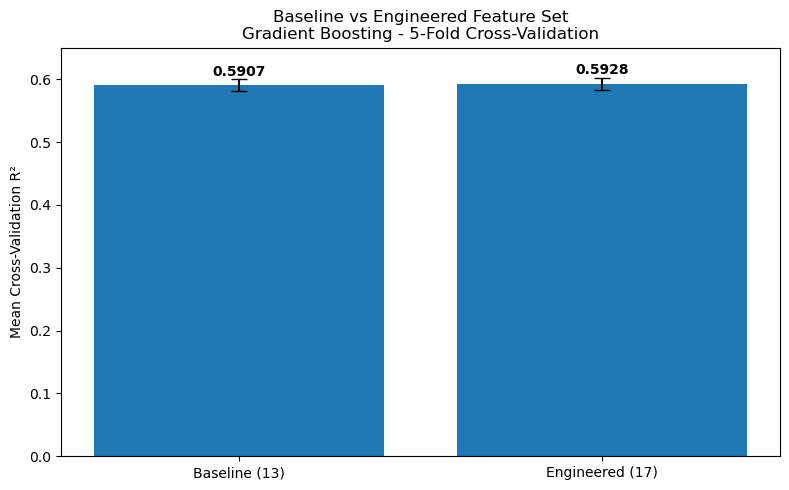

In [ ]:
# ============================================================
# Feature Engineering Comparison Plot
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

labels = ['Baseline (13)', 'Engineered (17)']

cv_scores = [
    baseline_cv.mean(),
    engineered_cv.mean()
]

cv_errors = [
    baseline_cv.std(),
    engineered_cv.std()
]

ax.bar(
    labels,
    cv_scores,
    yerr=cv_errors,
    capsize=6
)

ax.set_ylabel('Mean Cross-Validation R²')
ax.set_title(
    'Baseline vs Engineered Feature Set\n'
    'Gradient Boosting - 5-Fold Cross-Validation'
)

ax.set_ylim(0, 0.65)

for i, score in enumerate(cv_scores):
    ax.text(
        i,
        score + 0.015,
        f'{score:.4f}',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()

# Save figure
plt.savefig(
    '../../../results/figures/'
    'feature_engineering_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
# ============================================================
# Gradient Boosting - Actual vs Predicted + Residual Analysis
# Baseline diagnostic only
# ============================================================

# Prediction from current fitted Gradient Boosting baseline
y_pred_log = pipeline_gb.predict(X_test)

# Convert back to original EUR scale
y_actual_eur = np.expm1(y_test)
y_pred_eur = np.expm1(y_pred_log)

# Residual = Actual - Predicted
residuals = y_actual_eur - y_pred_eur

print(f"Number of predictions: {len(y_pred_eur):,}")
print(f"Mean residual: €{residuals.mean():,.0f}")
print(f"Median residual: €{np.median(residuals):,.0f}")

Number of predictions: 5,606
Mean residual: €897,852
Median residual: €-3,120


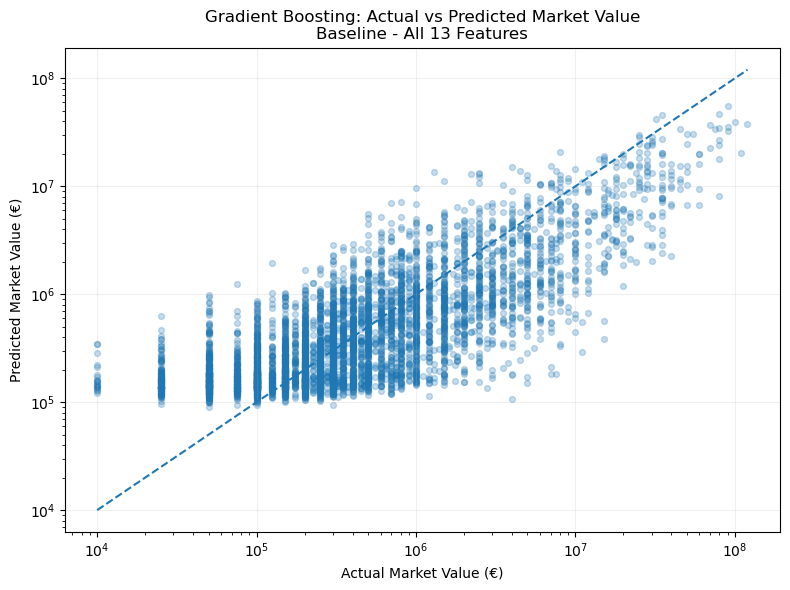

In [ ]:
# Actual & Predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    y_actual_eur,
    y_pred_eur,
    alpha=0.25,
    s=18
)

min_value = min(y_actual_eur.min(), y_pred_eur.min())
max_value = max(y_actual_eur.max(), y_pred_eur.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Actual Market Value (€)')
plt.ylabel('Predicted Market Value (€)')
plt.title(
    'Gradient Boosting: Actual vs Predicted Market Value\n'
    'Baseline - All 13 Features'
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    '../../../results/figures/ml/actual_vs_predicted_gb_baseline.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

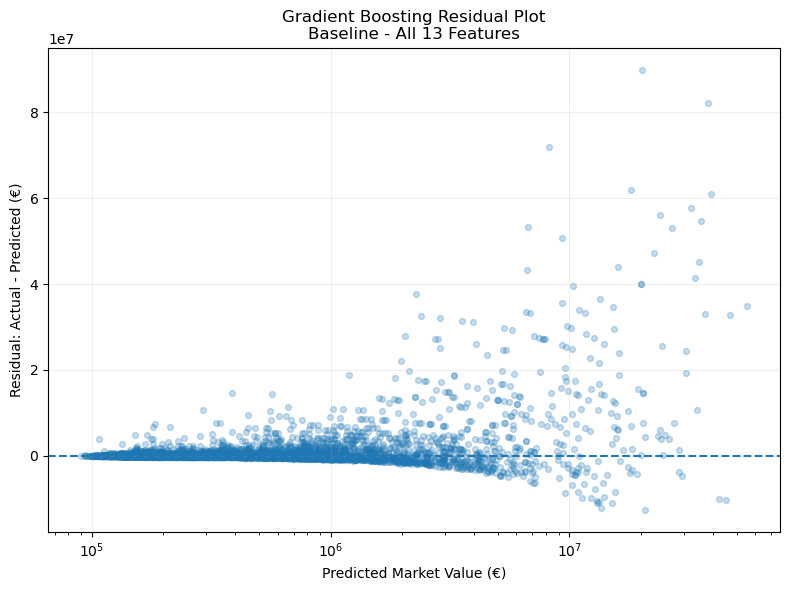

In [ ]:
# Residual Plot

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_eur,
    residuals,
    alpha=0.25,
    s=18
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xscale('log')

plt.xlabel('Predicted Market Value (€)')
plt.ylabel('Residual: Actual - Predicted (€)')
plt.title(
    'Gradient Boosting Residual Plot\n'
    'Baseline - All 13 Features'
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    '../../../results/figures/ml/residual_plot_gb_baseline.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
# Save Models

# Save all 3 models
joblib.dump(pipeline_lr, '../../../models/model_linear_regression.pkl')
joblib.dump(pipeline_rf, '../../../models/model_random_forest.pkl')
joblib.dump(pipeline_gb, '../../../models/model_gradient_boosting.pkl')

# Save encoders
joblib.dump(le_position, '../../../models/encoder_position.pkl')
joblib.dump(le_sub,      '../../../models/encoder_sub_position.pkl')

# Save feature list
with open('../../../models/features.json', 'w') as f:
    json.dump(FEATURES, f)

print(" All models saved:")
print("  → models/model_linear_regression.pkl")
print("  → models/model_random_forest.pkl")
print("  → models/model_gradient_boosting.pkl")
print("  → models/encoder_position.pkl")
print("  → models/encoder_sub_position.pkl")
print("  → models/features.json")

 All models saved:
  → models/model_linear_regression.pkl
  → models/model_random_forest.pkl
  → models/model_gradient_boosting.pkl
  → models/encoder_position.pkl
  → models/encoder_sub_position.pkl
  → models/features.json


In [ ]:
import os

files = [
    '../../../models/model_linear_regression.pkl',
    '../../../models/model_random_forest.pkl',
    '../../../models/model_gradient_boosting.pkl',
    '../../../models/encoder_position.pkl',
    '../../../models/encoder_sub_position.pkl',
    '../../../models/features.json'
]

for f in files:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1024
        print(f"✅ {f.split('/')[-1]:<40} {size:>8.1f} KB")
    else:
        print(f"❌ {f} NOT FOUND")

✅ model_linear_regression.pkl                   2.4 KB
✅ model_random_forest.pkl                  175509.4 KB
✅ model_gradient_boosting.pkl                 194.9 KB
✅ encoder_position.pkl                          0.6 KB
✅ encoder_sub_position.pkl                      0.8 KB
✅ features.json                                 0.2 KB


In [29]:
# ============================================================
# Baseline Model Comparison - Summary
# ============================================================

# Get model results
lr_result = results_df.loc[
    results_df['Model'] == 'Linear Regression'
].iloc[0]

rf_result = results_df.loc[
    results_df['Model'] == 'Random Forest'
].iloc[0]

gb_result = results_df.loc[
    results_df['Model'] == 'Gradient Boosting'
].iloc[0]

# Get cross-validation results
lr_cv = cv_df.loc[
    cv_df['Model'] == 'Linear Regression'
].iloc[0]

rf_cv = cv_df.loc[
    cv_df['Model'] == 'Random Forest'
].iloc[0]

gb_cv = cv_df.loc[
    cv_df['Model'] == 'Gradient Boosting'
].iloc[0]

print("=" * 60)
print("BASELINE MODEL COMPARISON — SUMMARY")
print("=" * 60)

print(f"""
Dataset:
  Total players : {len(df):,}
  Train size    : {len(X_train):,} (80%)
  Test size     : {len(X_test):,} (20%)
  Baseline Features : {len(FEATURES)}

Model Results (Test Set):
  Linear Regression  → R²: {lr_result['R2']:.4f}
  Random Forest      → R²: {rf_result['R2']:.4f}
  Gradient Boosting  → R²: {gb_result['R2']:.4f} -> Best

Cross Validation (5-Fold):
  Linear Regression  → {lr_cv['CV_R2_Mean']:.4f} ± {lr_cv['CV_R2_Std']:.4f}
  Random Forest      → {rf_cv['CV_R2_Mean']:.4f} ± {rf_cv['CV_R2_Std']:.4f}
  Gradient Boosting  → {gb_cv['CV_R2_Mean']:.4f} ± {gb_cv['CV_R2_Std']:.4f}

Top 3 Important Features:
  1. {feature_importance.iloc[0]['Feature']} ({feature_importance.iloc[0]['Importance']:.4f})
  2. {feature_importance.iloc[1]['Feature']} ({feature_importance.iloc[1]['Importance']:.4f})
  3. {feature_importance.iloc[2]['Feature']} ({feature_importance.iloc[2]['Importance']:.4f})

Best Performing Model: Gradient Boosting
Reason: Highest Test R² and highest mean 5-fold CV R²,
        with relatively consistent performance across folds.
""")

BASELINE MODEL COMPARISON — SUMMARY

Dataset:
  Total players : 28,028
  Train size    : 22,422 (80%)
  Test size     : 5,606 (20%)
  Baseline Features : 13

Model Results (Test Set):
  Linear Regression  → R²: 0.3921
  Random Forest      → R²: 0.5772
  Gradient Boosting  → R²: 0.5978 -> Best

Cross Validation (5-Fold):
  Linear Regression  → 0.3720 ± 0.0038
  Random Forest      → 0.5768 ± 0.0103
  Gradient Boosting  → 0.5901 ± 0.0097

Top 3 Important Features:
  1. international_caps (0.3027)
  2. age (0.1887)
  3. total_minutes (0.1271)

Best Performing Model: Gradient Boosting
Reason: Highest Test R² and highest mean 5-fold CV R²,
        with relatively consistent performance across folds.



In [32]:
# ============================================================
# Experiment 1 - Final Summary
# ============================================================

baseline_final = feature_engineering_results.loc[
    feature_engineering_results['Feature_Set'] == 'Baseline (13)'
].iloc[0]

engineered_final = feature_engineering_results.loc[
    feature_engineering_results['Feature_Set'] == 'Engineered (17)'
].iloc[0]

# Improvement from feature engineering
delta_cv_r2 = (
    engineered_final['CV_R2_Mean']
    - baseline_final['CV_R2_Mean']
)

delta_test_r2 = (
    engineered_final['Test_R2']
    - baseline_final['Test_R2']
)

delta_mae = (
    baseline_final['Test_MAE_EUR']
    - engineered_final['Test_MAE_EUR']
)

delta_rmse = (
    baseline_final['Test_RMSE_EUR']
    - engineered_final['Test_RMSE_EUR']
)

print("=" * 70)
print("EXPERIMENT 1 — FINAL SUMMARY")
print("=" * 70)

print(f"""
Task:
  Cross-Sectional Football Market Value Estimation

Dataset:
  Total players : {len(df):,}
  Train size    : {len(X_train):,}
  Test size     : {len(X_test):,}

Baseline Model:
  Algorithm     : Gradient Boosting
  Features      : {int(baseline_final['N_Features'])}
  CV R²         : {baseline_final['CV_R2_Mean']:.4f} ± {baseline_final['CV_R2_Std']:.4f}
  Test R²       : {baseline_final['Test_R2']:.4f}
  Test MAE      : €{baseline_final['Test_MAE_EUR']:,.0f}
  Test RMSE     : €{baseline_final['Test_RMSE_EUR']:,.0f}

Final Engineered Model:
  Algorithm     : Gradient Boosting
  Features      : {int(engineered_final['N_Features'])}
  CV R²         : {engineered_final['CV_R2_Mean']:.4f} ± {engineered_final['CV_R2_Std']:.4f}
  Test R²       : {engineered_final['Test_R2']:.4f}
  Test MAE      : €{engineered_final['Test_MAE_EUR']:,.0f}
  Test RMSE     : €{engineered_final['Test_RMSE_EUR']:,.0f}

Feature Engineering Improvement:
  CV R² change  : {delta_cv_r2:+.4f}
  Test R² change: {delta_test_r2:+.4f}
  MAE reduction : €{delta_mae:,.0f}
  RMSE reduction: €{delta_rmse:,.0f}

Final Experiment 1 Model:
  Gradient Boosting with 17 engineered features

Conclusion:
  The engineered feature set produced a small but consistent
  improvement over the 13-feature baseline.
""")

EXPERIMENT 1 — FINAL SUMMARY

Task:
  Cross-Sectional Football Market Value Estimation

Dataset:
  Total players : 28,028
  Train size    : 22,422
  Test size     : 5,606

Baseline Model:
  Algorithm     : Gradient Boosting
  Features      : 13
  CV R²         : 0.5901 ± 0.0097
  Test R²       : 0.5978
  Test MAE      : €1,318,255
  Test RMSE     : €4,828,948

Final Engineered Model:
  Algorithm     : Gradient Boosting
  Features      : 17
  CV R²         : 0.5922 ± 0.0094
  Test R²       : 0.5984
  Test MAE      : €1,322,441
  Test RMSE     : €4,873,511

Feature Engineering Improvement:
  CV R² change  : +0.0020
  Test R² change: +0.0007
  MAE reduction : €-4,186
  RMSE reduction: €-44,563

Final Experiment 1 Model:
  Gradient Boosting with 17 engineered features

Conclusion:
  The engineered feature set produced a small but consistent
  improvement over the 13-feature baseline.

